# Emotion Classification with Attention - GoEmotions
Classify Reddit comments into 6 core emotions (joy, sadness, anger, fear, surprise, disgust).
Four models compared on the same data: LSTM, GRU, BiLSTM + Attention (built from scratch in PyTorch, GloVe embeddings) and a fine-tuned DistilBERT (HuggingFace Trainer).
Attention weights are plotted as heatmaps to show which words drive each prediction. The best model is deployed as a Gradio app.

In [1]:
# ---- Imports & Global Settings ----
import os, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, ConfusionMatrixDisplay)

import emotion_utils as eu      # our own file: data loading, cleaning, vocab, GloVe, models (shared with the app)

SKIP_HF = os.environ.get("SKIP_HF", "0") == "1"   # set SKIP_HF=1 to skip DistilBERT (e.g. CPU-only machine)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("torch", torch.__version__)
os.makedirs("models", exist_ok=True)

Device: cuda | NVIDIA GeForce RTX 3060 Ti
torch 2.6.0+cu124


## 1. Load GoEmotions and map 28 labels -> 6 emotions
Google's official `ekman_mapping.json` groups the 27 fine emotions into 6 (e.g. annoyance -> anger). `neutral` has no mapping. A comment is kept only if all its labels point to exactly one emotion - mixed comments (joy + anger) can't teach a single-label classifier.

In [2]:
# ---- Load & Map to 6 Emotions ----
splits = eu.load_goemotions("data")
print("Raw rows:", {k: len(v) for k, v in splits.items()})
print(f"Comments with >1 label: {(splits['train']['fine'].str.len() > 1).mean():.1%}")

for name, df in splits.items():
    print(f"{name}: kept {df['emotion'].notna().sum()} of {len(df)} ({df['emotion'].notna().mean():.0%})")

train_df, val_df, test_df = [splits[s].dropna(subset=["emotion"]).reset_index(drop=True) for s in ("train", "val", "test")]

for df in (train_df, val_df, test_df):
    df["label"] = df["emotion"].map(eu.EMO2ID)
train_df[["text", "fine", "emotion"]].head()

Raw rows: {'train': 43410, 'val': 5426, 'test': 5427}
Comments with >1 label: 16.4%
train: kept 28104 of 43410 (65%)
val: kept 3527 of 5426 (65%)
test: kept 3539 of 5427 (65%)


,text,fine,emotion
0,WHY THE FUCK IS BAYLESS ISOING,[anger],anger
1,To make her feel threatened,[fear],fear
2,Dirty Southern Wankers,[annoyance],anger
3,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[surprise],surprise
4,Yes I heard abt the f bombs! That has to be wh...,[gratitude],joy


In [3]:
# ---- Class Distribution ----
dist = train_df["emotion"].value_counts()
print(pd.DataFrame({"count": dist, "share": (dist / dist.sum()).round(3)}).to_string())
print("\nImbalance ratio (biggest / smallest):", round(dist.max() / dist.min(), 1))

          count  share
emotion               
joy       15809  0.563
anger      4590  0.163
surprise   4160  0.148
sadness    2455  0.087
fear        566  0.020
disgust     524  0.019

Imbalance ratio (biggest / smallest): 30.2


Joy is ~56% of the data; fear and disgust only ~2% each. A model that always says *joy* gets ~56% accuracy - that is why we report Macro F1 (every class counts equally) and train with class weights.

## 2. Clean, tokenize, pad
Stop words are kept ("not", "so", "never" carry emotion, and the attention heatmap needs them). Post-padding: words first, zeros after; the models are told to ignore the zeros.

In [4]:
# ---- Text Cleaning ----
for df in (train_df, val_df, test_df):
    df["clean"] = df["text"].apply(eu.clean_text)
for raw in ["I don't think [NAME] is ever coming back :(", "This is so scary!!! 😱"]:
    print(f"{raw!r:48} -> {eu.clean_text(raw)!r}")
lens = train_df["clean"].str.split().str.len()
print("\nWords per comment: median", int(lens.median()), "| 95th pct", int(np.percentile(lens, 95)), "| max", lens.max())

"I don't think [NAME] is ever coming back :("    -> 'i do not think name is ever coming back'
'This is so scary!!! 😱'                          -> 'this is so scary'

Words per comment: median 13 | 95th pct 25 | max 31


In [5]:
# ---- Tokenizer & Padded Sequences ----
vocab = eu.Vocab(num_words=20000).fit(train_df["clean"])
vocab.save("models/vocab.json")
X_train, X_val, X_test = (vocab.encode(d["clean"].tolist()) for d in (train_df, val_df, test_df))
y_train, y_val, y_test = (d["label"].values for d in (train_df, val_df, test_df))
print("Vocabulary size (incl. padding):", len(vocab))
print("X_train shape:", X_train.shape)
print("Example:", train_df["clean"].iloc[2], "->", X_train[2][:10], "...")

Vocabulary size (incl. padding): 19661
X_train shape: (28104, 40)
Example: dirty southern wankers -> [1247 3477 5477    0    0    0    0    0    0    0] ...


## 3. GloVe embeddings
Each word ID gets its pre-trained 100-number GloVe vector, so the model starts out knowing *terrified ≈ scared*. The embeddings stay trainable so Reddit meanings can adjust (in news text "gross" mostly means *gross domestic product*).

In [6]:
# ---- GloVe Embedding Matrix ----
emb_matrix, glove, missing = eu.glove_matrix("data/glove_subset_100d.txt", vocab, dim=100)
counts = train_df["clean"].str.split().explode().value_counts()
print("emb_matrix shape:", emb_matrix.shape)
print(f"Words found in GloVe: {len(vocab.word_index) - len(missing)} / {len(vocab.word_index)}")
print(f"Word occurrences covered: {counts[counts.index.isin(glove.keys())].sum() / counts.sum():.1%}")
print("Most common missing:", counts[counts.index.isin(missing)].head(10).index.tolist())

emb_matrix shape: (19661, 100)
Words found in GloVe: 17532 / 19660
Word occurrences covered: 99.1%
Most common missing: ['lmao', 'hahaha', 'tbh', 'idk', 'subreddit', 'upvote', 'downvoted', 'downvote', 'dumbass', 'upvotes']


In [7]:
# ---- Class Weights for Imbalance ----
class_w = compute_class_weight("balanced", classes=np.arange(6), y=y_train)
print({e: round(w, 2) for e, w in zip(eu.EMOTIONS, class_w)})
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32, device=DEVICE))

{'anger': np.float64(1.02), 'disgust': np.float64(8.94), 'fear': np.float64(8.28), 'joy': np.float64(0.3), 'sadness': np.float64(1.91), 'surprise': np.float64(1.13)}


## 4. Training + evaluation helpers
Same loop for all three custom models: weighted loss, Adam, gradient clipping, early stopping on validation Macro F1 (keep the best epoch's weights).

In [8]:
# ---- Training + Evaluation Helpers ----
EPOCHS = 15
PATIENCE = 3
BATCH = 64
results, test_preds, test_probs, curves = {}, {}, {}, {}

def evaluate(name, y_true, y_pred, train_time):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    per = precision_recall_fscore_support(y_true, y_pred, labels=range(6), zero_division=0)
    results[name] = {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": p,
                     "recall_macro": r, "f1_macro": f1, "train_time_min": train_time / 60,
                     **{f"f1_{e}": per[2][i] for i, e in enumerate(eu.EMOTIONS)}}
    test_preds[name] = y_pred
    print(f"\n===== {name} - test set =====")
    print(classification_report(y_true, y_pred, labels=range(6), target_names=eu.EMOTIONS, digits=3, zero_division=0))

def train_custom(name):
    torch.manual_seed(SEED)
    model = eu.build_model(name, emb_matrix).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train)
    best_f1, best_state, bad, curve = -1, None, 0, []
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); total = 0
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            xb, yb = Xtr[idx].to(DEVICE), ytr[idx].to(DEVICE)
            opt.zero_grad()
            logits, _ = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)    # stop exploding gradients
            opt.step()
            total += loss.item() * len(idx)
        val_f1 = f1_score(y_val, eu.predict_proba(model, X_val, DEVICE)[0].argmax(1), average="macro")
        curve.append((total / len(Xtr), val_f1))
        print(f"epoch {epoch:2d} | train loss {total / len(Xtr):.4f} | val macro-F1 {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1, bad = val_f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"Early stop - best val macro-F1 {best_f1:.4f}"); break
    model.load_state_dict(best_state)
    train_time = time.time() - t0
    curves[name] = curve
    probs, _ = eu.predict_proba(model, X_test, DEVICE)
    test_probs[name] = probs
    evaluate(name, y_test, probs.argmax(1), train_time)
    os.makedirs(f"models/{name}", exist_ok=True)
    torch.save(model.state_dict(), f"models/{name}/weights.pt")
    return model

## 5. LSTM

In [9]:
# ---- Train LSTM ----
lstm = train_custom("LSTM")

epoch  1 | train loss 1.5929 | val macro-F1 0.4067


epoch  2 | train loss 1.2314 | val macro-F1 0.5360


epoch  3 | train loss 1.0016 | val macro-F1 0.5689


epoch  4 | train loss 0.8972 | val macro-F1 0.6179


epoch  5 | train loss 0.7890 | val macro-F1 0.6213


epoch  6 | train loss 0.7196 | val macro-F1 0.5972


epoch  7 | train loss 0.6445 | val macro-F1 0.6032


epoch  8 | train loss 0.5783 | val macro-F1 0.5921
Early stop - best val macro-F1 0.6213

===== LSTM - test set =====
              precision    recall  f1-score   support

       anger      0.578     0.611     0.594       609
     disgust      0.403     0.675     0.505        77
        fear      0.570     0.765     0.653        85
         joy      0.904     0.782     0.839      1937
     sadness      0.575     0.654     0.612       298
    surprise      0.537     0.644     0.585       533

    accuracy                          0.718      3539
   macro avg      0.595     0.688     0.631      3539
weighted avg      0.746     0.718     0.728      3539



## 6. GRU

In [10]:
# ---- Train GRU ----
gru = train_custom("GRU")

epoch  1 | train loss 1.5708 | val macro-F1 0.4439


epoch  2 | train loss 1.1306 | val macro-F1 0.5847


epoch  3 | train loss 0.9442 | val macro-F1 0.6043


epoch  4 | train loss 0.8520 | val macro-F1 0.6027


epoch  5 | train loss 0.7660 | val macro-F1 0.6142


epoch  6 | train loss 0.6924 | val macro-F1 0.6022


epoch  7 | train loss 0.6327 | val macro-F1 0.6025


epoch  8 | train loss 0.5685 | val macro-F1 0.6099
Early stop - best val macro-F1 0.6142

===== GRU - test set =====
              precision    recall  f1-score   support

       anger      0.597     0.603     0.600       609
     disgust      0.406     0.701     0.514        77
        fear      0.535     0.800     0.642        85
         joy      0.935     0.746     0.830      1937
     sadness      0.587     0.634     0.610       298
    surprise      0.489     0.730     0.585       533

    accuracy                          0.710      3539
   macro avg      0.591     0.702     0.630      3539
weighted avg      0.759     0.710     0.723      3539



## 7. BiLSTM + Attention
A plain LSTM/GRU judges the comment from its last hidden state only. Attention instead looks at every word's state and learns how much each one matters:
1. BiLSTM reads the comment left->right and right->left, so each word's state knows its full context.
2. Score each word: `score_t = v . tanh(W*h_t + b)`.
3. Mask padding (score = −∞) so zeros can't get attention.
4. Softmax turns scores into weights α that are positive and sum to 1.
5. Context = sum of α_t * h_t (a weighted average) -> classifier.

The α weights are exactly what the heatmaps below show.

In [11]:
# ---- Train BiLSTM + Attention ----
bilstm_att = train_custom("BiLSTM+Attention")

epoch  1 | train loss 1.3896 | val macro-F1 0.5631


epoch  2 | train loss 1.0384 | val macro-F1 0.5965


epoch  3 | train loss 0.9246 | val macro-F1 0.6049


epoch  4 | train loss 0.8345 | val macro-F1 0.6084


epoch  5 | train loss 0.7520 | val macro-F1 0.6225


epoch  6 | train loss 0.7007 | val macro-F1 0.6142


epoch  7 | train loss 0.6322 | val macro-F1 0.6259


epoch  8 | train loss 0.5784 | val macro-F1 0.6206


epoch  9 | train loss 0.5287 | val macro-F1 0.6124


epoch 10 | train loss 0.4789 | val macro-F1 0.6088
Early stop - best val macro-F1 0.6259

===== BiLSTM+Attention - test set =====
              precision    recall  f1-score   support

       anger      0.626     0.619     0.623       609
     disgust      0.467     0.636     0.538        77
        fear      0.504     0.835     0.628        85
         joy      0.927     0.789     0.852      1937
     sadness      0.525     0.668     0.588       298
    surprise      0.549     0.683     0.609       533

    accuracy                          0.731      3539
   macro avg      0.600     0.705     0.640      3539
weighted avg      0.764     0.731     0.742      3539



## 8. Attention heatmaps - which words drive the prediction?
One correctly-classified test comment per emotion. Darker red = more attention.

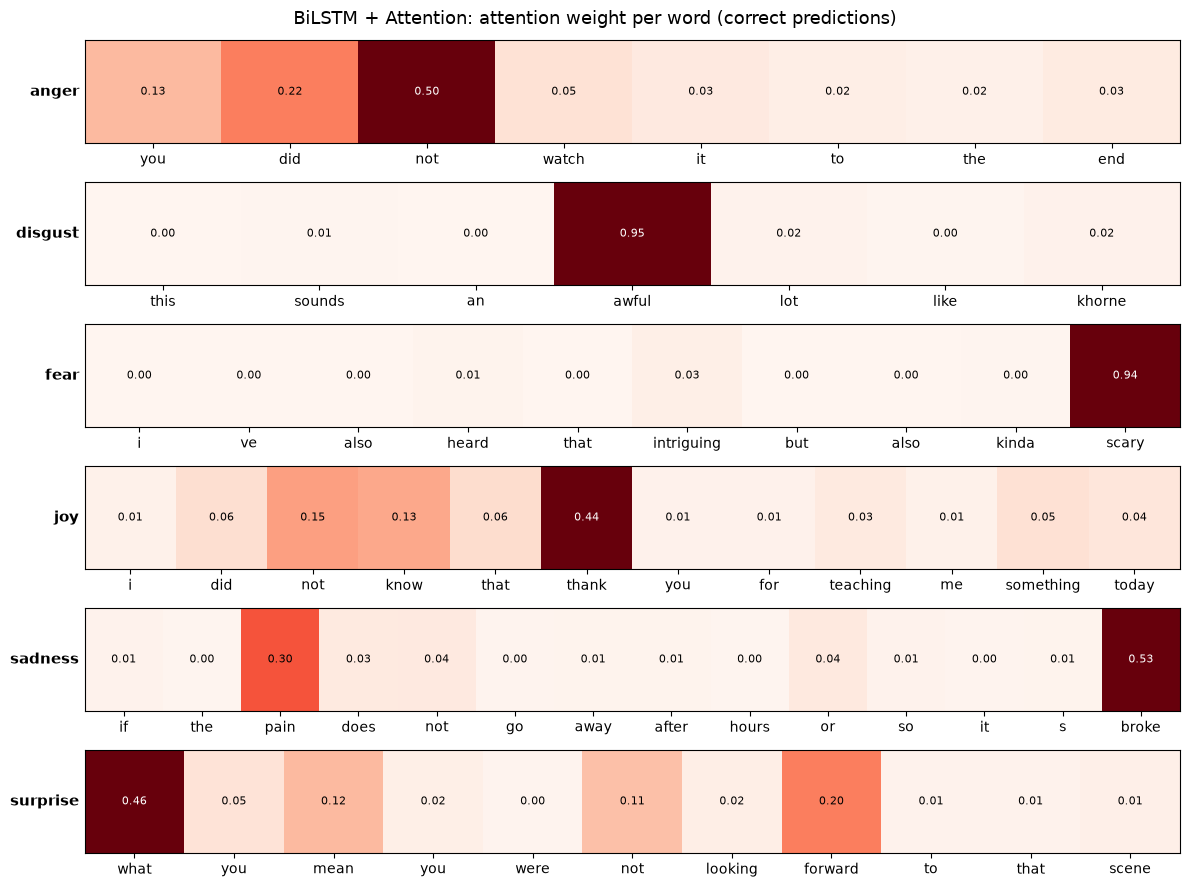

In [12]:
# ---- Attention Heatmaps per Emotion ----
probs_att, att = eu.predict_proba(bilstm_att, X_test, DEVICE)
pred_att = probs_att.argmax(1)

fig, axes = plt.subplots(6, 1, figsize=(12, 9))
for ax, e in zip(axes, eu.EMOTIONS):
    k = eu.EMO2ID[e]
    cand = [i for i in range(len(y_test)) if y_test[i] == k and pred_att[i] == k
            and 5 <= len(test_df["clean"].iloc[i].split()) <= 14]
    if not cand:
        ax.axis("off"); continue
    i = cand[0]
    words = test_df["clean"].iloc[i].split()[:eu.MAX_LEN]
    w = att[i, :len(words)][None, :]                       # 1 row x n words
    ax.imshow(w, cmap="Reds", aspect="auto", vmin=0, vmax=w.max())
    ax.set_xticks(range(len(words))); ax.set_xticklabels(words, fontsize=10)
    ax.set_yticks([]); ax.set_ylabel(e, rotation=0, ha="right", va="center", fontsize=11, fontweight="bold")
    for j, v in enumerate(w[0]):
        ax.text(j, 0, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.6 * w.max() else "black")
fig.suptitle("BiLSTM + Attention: attention weight per word (correct predictions)", fontsize=13)
plt.tight_layout(); plt.show()

In [13]:
# ---- Most-Attended Words per Predicted Emotion ----
rows = {}
for e in eu.EMOTIONS:
    k = eu.EMO2ID[e]; score = {}; freq = {}
    for i in np.where(pred_att == k)[0]:
        for j, wd in enumerate(test_df["clean"].iloc[i].split()[:eu.MAX_LEN]):
            score[wd] = score.get(wd, 0) + att[i, j]; freq[wd] = freq.get(wd, 0) + 1
    avg = {wd: score[wd] / freq[wd] for wd in score if freq[wd] >= 3}   # words seen >= 3 times
    rows[e] = ", ".join(sorted(avg, key=avg.get, reverse=True)[:8])
pd.DataFrame.from_dict(rows, orient="index", columns=["highest average attention"])

,highest average attention
anger,"piss, angry, annoying, hell, rude, pissed, hat..."
disgust,"weird, worst, worse, disgusting, ugly, awful, ..."
fear,"creepy, scary, fear, afraid, cringe, worried, ..."
joy,"careful, cheers, lovely, hopefully, hilarious,..."
sadness,"upset, awkward, disappointing, disappointed, w..."
surprise,"surprise, curious, wondering, surprised, omg, ..."


## 9. Fine-tuned Transformer - DistilBERT (HuggingFace Trainer)
The transformer gets the raw text (its own sub-word tokenizer handles punctuation, emojis and casing). Same class weights through a custom `compute_loss`.

In [14]:
# ---- Transformer Settings & Tokenizer ----
if not SKIP_HF:
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              TrainingArguments, Trainer, DataCollatorWithPadding)
    MODEL_NAME = "distilbert-base-uncased"
    TF_MAX_LEN = 64                      # comments are short (max 31 words)
    TF_EPOCHS = 3
    hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    print("Example tokens:", hf_tokenizer.tokenize("I'm sooo excited for tomorrow!! 😂"))

    class EmoDataset(torch.utils.data.Dataset):
        def __init__(self, texts, labels):
            self.enc = hf_tokenizer(list(texts), truncation=True, max_length=TF_MAX_LEN)
            self.labels = list(labels)
        def __len__(self):
            return len(self.labels)
        def __getitem__(self, i):
            item = {k: v[i] for k, v in self.enc.items()}
            item["labels"] = int(self.labels[i])
            return item

    train_ds, val_ds, test_ds = (EmoDataset(d["text"], d["label"]) for d in (train_df, val_df, test_df))
    print("Transformer train rows:", len(train_ds), "| val:", len(val_ds))

Example tokens: ['i', "'", 'm', 'soo', '##o', 'excited', 'for', 'tomorrow', '!', '!', '[UNK]']


Transformer train rows: 28104 | val: 3527


In [15]:
# ---- Trainer with Class-Weighted Loss ----
if not SKIP_HF:
    cw_tensor = torch.tensor(class_w, dtype=torch.float)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = nn.CrossEntropyLoss(weight=cw_tensor.to(outputs.logits.device))(outputs.logits, labels)
            return (loss, outputs) if return_outputs else loss

    def hf_metrics(eval_pred):
        logits, labels = eval_pred
        preds = logits.argmax(-1)
        return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}

    id2label = dict(enumerate(eu.EMOTIONS))
    tf_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=6, id2label=id2label, label2id=eu.EMO2ID)

    BATCH_TF = 32
    total_steps = int(np.ceil(len(train_ds) / BATCH_TF)) * TF_EPOCHS
    args = TrainingArguments(
        output_dir="models/hf_checkpoints",
        num_train_epochs=TF_EPOCHS,
        per_device_train_batch_size=BATCH_TF,
        per_device_eval_batch_size=128,
        learning_rate=3e-5,
        weight_decay=0.01,
        warmup_steps=int(0.06 * total_steps),
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=200,
        fp16=(DEVICE == "cuda"),
        report_to="none",
        dataloader_num_workers=0,
        seed=SEED,
    )
    trainer = WeightedTrainer(model=tf_model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                              data_collator=DataCollatorWithPadding(hf_tokenizer), compute_metrics=hf_metrics)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [16]:
# ---- Fine-tune DistilBERT ----
if not SKIP_HF:
    t0 = time.time()
    trainer.train()
    tf_time = time.time() - t0
    logits = trainer.predict(test_ds).predictions
    test_probs["DistilBERT"] = torch.softmax(torch.tensor(logits), -1).numpy()
    evaluate("DistilBERT", y_test, logits.argmax(-1), tf_time)
    trainer.save_model("models/DistilBERT")
    hf_tokenizer.save_pretrained("models/DistilBERT")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.829294,0.741107,0.783952,0.675292
2,0.624832,0.760297,0.787071,0.683803
3,0.441633,0.828561,0.802949,0.696922



===== DistilBERT - test set =====
              precision    recall  f1-score   support

       anger      0.688     0.695     0.691       609
     disgust      0.447     0.597     0.511        77
        fear      0.648     0.800     0.716        85
         joy      0.938     0.864     0.900      1937
     sadness      0.621     0.688     0.653       298
    surprise      0.697     0.786     0.739       533

    accuracy                          0.801      3539
   macro avg      0.673     0.738     0.702      3539
weighted avg      0.814     0.801     0.806      3539



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 10. Compare the four models

In [17]:
# ---- Model Comparison Table ----
comparison = pd.DataFrame(results).T.sort_values("f1_macro", ascending=False)
comparison.round(3)

,accuracy,precision_macro,recall_macro,f1_macro,train_time_min,f1_anger,f1_disgust,f1_fear,f1_joy,f1_sadness,f1_surprise
DistilBERT,0.801,0.673,0.738,0.702,1.878,0.691,0.511,0.716,0.900,0.653,0.739
BiLSTM+Attention,0.731,0.600,0.705,0.640,0.537,0.623,0.538,0.628,0.852,0.588,0.609
LSTM,0.718,0.595,0.688,0.631,0.274,0.594,0.505,0.653,0.839,0.612,0.585
GRU,0.710,0.591,0.702,0.630,0.199,0.600,0.514,0.642,0.830,0.610,0.585


Reading the confusion matrices: rows = true emotion, columns = predicted. Each row is normalized to 1, so the diagonal is the recall of that emotion (share of e.g. real *fear* comments the model caught). Off-diagonal cells show what it gets confused with.

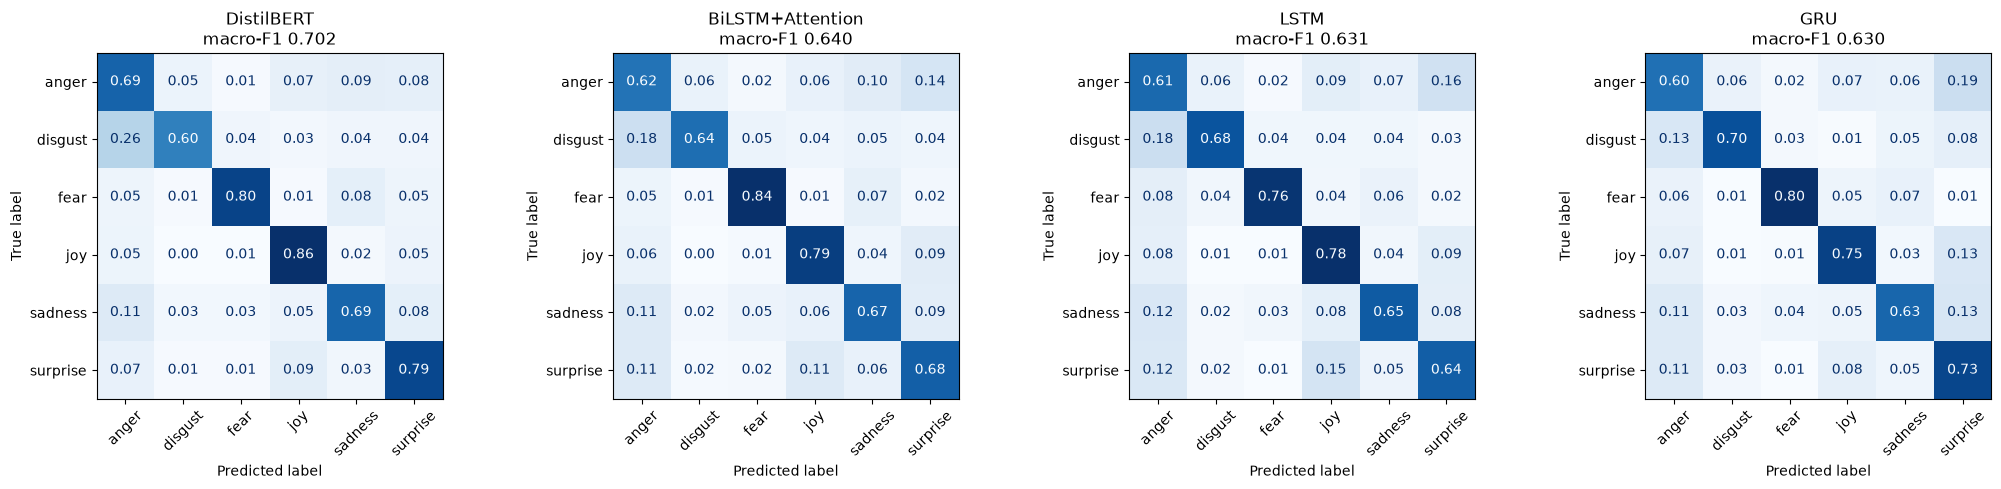

In [18]:
# ---- Confusion Matrices (row-normalized) ----
names = list(comparison.index)
fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.8))
axes = np.atleast_1d(axes)
for ax, n in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(y_test, test_preds[n], labels=range(6), display_labels=eu.EMOTIONS,
                                            normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{n}\nmacro-F1 {results[n]['f1_macro']:.3f}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 11. Classify new comments with the best model

In [19]:
# ---- Best Model & New Predictions ----
BEST = comparison.index[0]
print("Best model (macro-F1):", BEST)
custom = {"LSTM": lstm, "GRU": gru, "BiLSTM+Attention": bilstm_att}

def predict_emotion(texts):
    if BEST == "DistilBERT":
        enc = hf_tokenizer(texts, truncation=True, max_length=TF_MAX_LEN, padding=True, return_tensors="pt").to(tf_model.device)
        with torch.no_grad():
            return torch.softmax(tf_model(**enc).logits, -1).cpu().numpy()
    return eu.predict_proba(custom[BEST], vocab.encode([eu.clean_text(t) for t in texts]), DEVICE)[0]

new = ["I can't believe they cancelled the show, I'm devastated",
       "Wow, I had no idea that was even possible!",
       "That smell in the fridge is absolutely revolting",
       "I'm so nervous about my exam tomorrow",
       "This is the best day of my life, thank you all!",
       "Stop lying to everyone, it's pathetic"]
P = predict_emotion(new)
pd.DataFrame({"comment": new, "predicted": [eu.EMOTIONS[i] for i in P.argmax(1)],
              "confidence": P.max(1).round(3)})

Best model (macro-F1): DistilBERT


,comment,predicted,confidence
0,"I can't believe they cancelled the show, I'm d...",sadness,0.975
1,"Wow, I had no idea that was even possible!",surprise,0.962
2,That smell in the fridge is absolutely revolting,disgust,0.845
3,I'm so nervous about my exam tomorrow,fear,0.993
4,"This is the best day of my life, thank you all!",joy,0.992
5,"Stop lying to everyone, it's pathetic",anger,0.520


In [20]:
# ---- Save results for the app + README ----
with open("models/results.json", "w") as f:
    json.dump({"best_model": BEST, "emotions": eu.EMOTIONS, "max_len": eu.MAX_LEN,
               "results": comparison.round(4).to_dict(orient="index")}, f, indent=2)
print("Saved models/results.json")

Saved models/results.json
